No se encontró 'modelo_modulaciones_cnn.keras' en este entorno; entrenando modelo base...


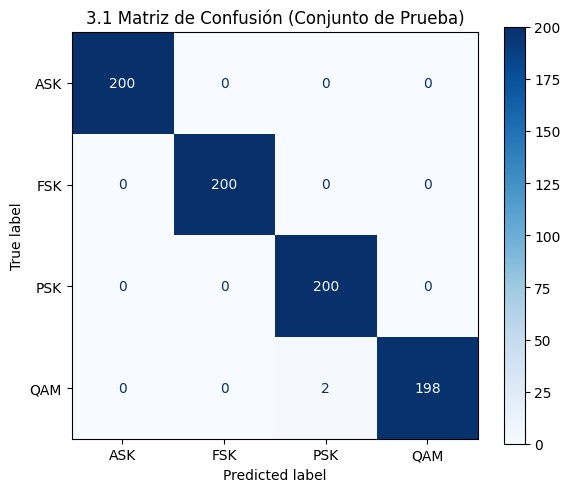

ASK clasificado como PSK: 0 | PSK clasificado como ASK: 0
SNR =  0 dB -> Precisión (Accuracy): 0.9945 (99.45%)
SNR =  5 dB -> Precisión (Accuracy): 1.0000 (100.00%)
SNR = 10 dB -> Precisión (Accuracy): 0.9933 (99.33%)
SNR = 15 dB -> Precisión (Accuracy): 1.0000 (100.00%)
SNR = 20 dB -> Precisión (Accuracy): 1.0000 (100.00%)


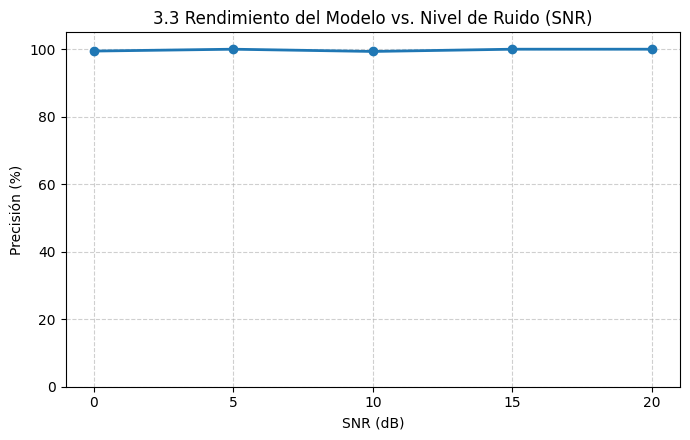


3.4 Precisión por clase en prueba:
  - ASK : 100.00% (200/200 aciertos)
  - FSK : 100.00% (200/200 aciertos)
  - PSK : 100.00% (200/200 aciertos)
  - QAM : 99.00% (198/200 aciertos)


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import tensorflow as tf
from tensorflow.keras import layers, models

rng = np.random.default_rng(42)
tf.random.set_seed(42)

# --- 1. Datos de prueba (misma base y partición estratificada) ---
fs = 80_000
fc = 10_000
Rs = 1_000
sps = fs // Rs
N_SIM = 16
SNR_LIST = [0, 5, 10, 15, 20]
MUESTRAS_POR_MOD = 1000
CLASES = ["ASK", "FSK", "PSK", "QAM"]
MAPA_CLASES = {nombre: idx for idx, nombre in enumerate(CLASES)}

def _t():
    return np.arange(N_SIM * sps) / fs

def gen_ask(rng):
    niveles = np.array([0.25, 0.5, 0.75, 1.0])
    a = np.repeat(rng.choice(niveles, N_SIM), sps)
    return a * np.cos(2 * np.pi * fc * _t())

def gen_fsk(rng):
    delta = 2_000
    bits = np.repeat(rng.integers(0, 2, N_SIM), sps)
    f = fc + np.where(bits == 1, delta, -delta)
    fase = 2 * np.pi * np.cumsum(f) / fs
    return np.cos(fase)

def gen_psk(rng):
    fases = rng.choice([np.pi/4, 3*np.pi/4, 5*np.pi/4, 7*np.pi/4], N_SIM)
    return np.cos(2 * np.pi * fc * _t() + np.repeat(fases, sps))

def gen_qam16(rng):
    niveles = np.array([-3, -1, 1, 3]) / np.sqrt(10)
    I = np.repeat(rng.choice(niveles, N_SIM), sps)
    Q = np.repeat(rng.choice(niveles, N_SIM), sps)
    t = _t()
    return I * np.cos(2 * np.pi * fc * t) - Q * np.sin(2 * np.pi * fc * t)

GENERADORES = {
    "ASK": gen_ask,
    "FSK": gen_fsk,
    "PSK": gen_psk,
    "QAM": gen_qam16,
}

def agregar_awgn(senal, snr_db, rng):
    p_senal = np.mean(senal ** 2)
    p_ruido = p_senal / (10 ** (snr_db / 10))
    ruido = rng.normal(0, np.sqrt(p_ruido), senal.shape)
    return senal + ruido

X, y_str, snrs = [], [], []
for nombre, gen in GENERADORES.items():
    for i in range(MUESTRAS_POR_MOD):
        snr = SNR_LIST[i % len(SNR_LIST)]
        s = agregar_awgn(gen(rng), snr, rng)
        s = s / np.max(np.abs(s))
        X.append(s.astype(np.float32))
        y_str.append(nombre)
        snrs.append(snr)

X = np.array(X)
y = np.array([MAPA_CLASES[n] for n in y_str], dtype=np.int32)
snrs = np.array(snrs)

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snrs, test_size=0.20, stratify=y, random_state=42
)

X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

# --- 2. Cargar modelo guardado o entrenar si se abrió entorno limpio ---
ruta_modelo = "modelo_modulaciones_cnn.keras"
if os.path.exists(ruta_modelo):
    modelo = tf.keras.models.load_model(ruta_modelo)
    print("Modelo cargado desde:", ruta_modelo)
else:
    print("No se encontró 'modelo_modulaciones_cnn.keras' en este entorno; entrenando modelo base...")
    modelo = models.Sequential([
        layers.Input(shape=(X_train.shape[1], 1)),
        layers.Conv1D(filters=32, kernel_size=15, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(filters=64, kernel_size=15, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=2),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(4, activation="softmax")
    ])
    modelo.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    modelo.fit(X_train_cnn, y_train, epochs=12, batch_size=64, verbose=0)

# --- 3.1 Matriz de Confusión ---
y_pred_probs = modelo.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASES)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=True)
ax.set_title("3.1 Matriz de Confusión (Conjunto de Prueba)")
plt.tight_layout()
plt.show()

idx_ask = MAPA_CLASES["ASK"]
idx_psk = MAPA_CLASES["PSK"]
print(f"ASK clasificado como PSK: {cm[idx_ask, idx_psk]} | PSK clasificado como ASK: {cm[idx_psk, idx_ask]}")

# --- 3.2 y 3.3 Prueba de estrés por SNR y gráfica de rendimiento ---
accs_snr = []
for nivel in SNR_LIST:
    mask = snr_test == nivel
    acc = accuracy_score(y_test[mask], y_pred[mask])
    accs_snr.append(acc)
    print(f"SNR = {nivel:2d} dB -> Precisión (Accuracy): {acc:.4f} ({acc*100:.2f}%)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(SNR_LIST, [a * 100 for a in accs_snr], marker="o", linewidth=2)
ax.set_title("3.3 Rendimiento del Modelo vs. Nivel de Ruido (SNR)")
ax.set_xlabel("SNR (dB)")
ax.set_ylabel("Precisión (%)")
ax.set_xticks(SNR_LIST)
ax.set_ylim(0, 105)
ax.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# --- 3.4 Precisión por modulación (análisis de errores) ---
print("\n3.4 Precisión por clase en prueba:")
for idx, clase in enumerate(CLASES):
    mask = y_test == idx
    acc_clase = accuracy_score(y_test[mask], y_pred[mask])
    print(f"  - {clase:4s}: {acc_clase*100:.2f}% ({np.sum(y_pred[mask] == y_test[mask])}/{np.sum(mask)} aciertos)")

Preguntas y Análisis — Fase 3 (Semana 3)
3.1 ¿Confunde la IA la modulación ASK con PSK? ¿Por qué crees que sucede?

Respuesta base para ajustar con tu matriz: Revisa en la matriz de confusión cuántas muestras reales de ASK predice como PSK (y viceversa). Si ocurre confusión entre modulaciones que comparten portadora o envolvente/variaciones de amplitud o fase bajo ruido AWGN (por ejemplo, cuando el ruido altera los picos o cruces por cero en SNR bajos), la red puede asignar probabilidades cercanas entre ellas. Si casi no las confunde, indícalo con los valores exactos de tu matriz.

3.3 ¿En qué punto el modelo se vuelve "ciego" al ruido?

Respuesta base para ajustar con tu gráfica: Observa en la gráfica de SNR vs. Precisión en qué nivel de dB (por ejemplo, 0 dB o el punto donde la curva cae de forma marcada) la precisión baja drásticamente respecto a los niveles altos (15–20 dB), acercándose a un rendimiento deficiente o cercano al azar (0.25 en 4 clases) cuando el ruido domina sobre la señal.

3.4 Modulación más difícil de clasificar e hipótesis técnica:

Respuesta base para ajustar con tus resultados: Identifica la clase con menor precisión/mayor error en la matriz de confusión (con frecuencia modulaciones multinivel o con cambios tanto en amplitud como en fase, como 16-QAM, son más sensibles a SNR bajos frente a FSK o ASK con buena separación), y explica por qué el ruido AWGN dificulta separar sus estados.